# Worksheet 2: Apply a quantum Fourier transform $F$

**Task 2 of 5.** Input: your $|m\rangle$ from worksheet 1. Output: $F|m\rangle$.

```
 |0…0⟩ ─[ your X gates ]─► |m⟩ ─[ F ]─► F|m⟩
```

Why the QFT is in the protocol: $|m\rangle$ has all its weight on one basis state, so measuring it shows $m$ at once. After $F$ the message lives only in the **phases**, and phases are what the key will scramble in worksheet 3.

What you'll build, in this order:

1. the root of unity $\zeta$
2. $F$ for $n=2$ by hand
3. `dft_matrix(n)` in NumPy
4. properties of $F$ (you test them)
5. what $F|m\rangle$ looks like
6. the QFT as a Qiskit gate, and a check that it equals your matrix
7. the QFT built gate by gate (H, CPHASE, SWAP)
8. a circuit for $|m\rangle \to F|m\rangle$
9. why $F$ alone is not a lock

### How to use this worksheet

- **📖 Read** cells explain a concept. **✍️ On paper** cells ask you to work something out by hand first.
- **✏️ TODO** cells are yours: replace `None` or the `raise NotImplementedError` with your own code.
- **✅ Check** cells test what you wrote. They print ✅ (correct), ❌ (what is wrong, not how to fix it) or ⏳ (not done yet). **Don't move on until you get ✅.**
- **💡 Hints** are folded. Open them only if you are stuck; Hint 1 is gentle, the last one names the exact function or gate.
- **🔀 Options** tables list the different ways to do a step. Choose one, and write your choice and reason in the decision log at the end, which you can reuse in the report.


## Setup


In [1]:
# Setup (given — nothing to solve here)
# If a package is missing:  !pip install qiskit matplotlib
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector, Operator, DensityMatrix
from qiskit.circuit.library import QFTGate, DiagonalGate, UnitaryGate

from lock_checks import *     # the automatic checks + plot_circles (keep lock_checks.py in this folder)

np.set_printoptions(precision=3, suppress=True, linewidth=130)
print("Qiskit", qiskit.__version__, "ready")

Qiskit 2.5.2 ready


## Paste your work from worksheet 1

Copy your `ket` and `encode_message` (and `bits_of` if `encode_message` uses it) into the cell below. The checks make sure they still work.


In [25]:
# ✏️ paste from worksheet 1
N_DEMO, N = 4, 6
d_demo, d, M = 2**N_DEMO, 2**N, 2**N

def bits_of(m, n):
    return [(m >> q) & 1 for q in range(n)]

def ket(m, d):
    v = np.zeros(d, dtype=complex)
    v[m] = 1.0
    return v

def encode_message(m, n):
    qr = QuantumRegister(n, "msg")
    qc = QuantumCircuit(qr)
    for q in range(n):
        if (m >> q) & 1:
            qc.x(qr[q])
    return qc

In [26]:
check_dims(N_DEMO, N, d_demo, d, M)
check_ket(ket)
check_encode(encode_message)

✅ dimensions d and M — d_demo = 16, d = 64, M = 64
✅ ket(m, d) — length, normalization and position all correct
✅ encode_message(m, n) — every message prepares the right basis state (n = 3 and 6)


True

---

## Step 2.1: The definition, and the root of unity $\zeta$

📖 The QFT on $d=2^n$ basis states:

$$F|m\rangle=\frac1{\sqrt d}\sum_{x=0}^{d-1}e^{2\pi i\,mx/d}\,|x\rangle ,\qquad F_{x,m}=\frac{\zeta^{xm}}{\sqrt d},\quad \zeta=e^{2\pi i/d}.$$

How to read it:

- **Column $m$ of the matrix is the state $F|m\rangle$.**
- Every entry has the same size $1/\sqrt d$.
- The phase of entry $(x,m)$ is $2\pi mx/d$ radians ($360°\cdot mx/d$). $m$ acts like a **frequency** (course deck 3.9).

⚠️ **Sign convention.** The paper, the course and Qiskit use $e^{+2\pi i\dots}$. NumPy's `np.fft.fft` uses $e^{-2\pi i\dots}$, which is the _inverse_ direction. Keep that in mind if you look things up.

✍️ On paper: for $d=4$, what is $\zeta$? (Hint: a quarter turn on the unit circle.)


In [27]:
# ✏️ TODO 2.1: zeta for d = 4, computed from the formula (not typed in by hand)
zeta4 = np.exp(2j * np.pi / 4)

In [28]:
check_zeta(zeta4, 4)

✅ root of unity zeta — zeta = 1j


True

<details><summary>💡 Hint 1</summary>

$e^{i\varphi}$ in NumPy: `np.exp(1j * phi)`.

</details>


## Step 2.2: $F$ for $n=2$ by hand

✍️ On paper, fill the $4\times4$ matrix $F_{x,m}=\zeta^{xm}/2$ (rows $x=0..3$, columns $m=0..3$), using only $1, i, -1, -i$. Then type it in below **without loops**. That's the point: you did it by hand.

Look at column 1 afterwards: which phases does it have? And column 2?


In [29]:
# ✏️ TODO 2.2: type your hand-computed matrix (use 1j for i)
F2_hand = np.array([
    [1, 1, 1, 1],
    [1, 1j, -1, -1j],
    [1, -1, 1, -1],
    [1, -1j, -1, 1j],
], dtype=complex) / 2

In [30]:
check_F2_hand(F2_hand)

✅ F by hand for n = 2


True

<details><summary>💡 Hint 1</summary>

Row 0 and column 0 are all ones (before dividing by 2).

</details>

<details><summary>💡 Hint 2</summary>

Entry $(x,m)$ is $i^{xm}$; reduce the exponent mod 4.

</details>


## Step 2.3: `dft_matrix(n)` for any $n$

🔀 **Options**

| Option | How                                              | Comment                                    |
| ------ | ------------------------------------------------ | ------------------------------------------ |
| A      | double loop over $x$ and $m$                     | clearest                                   |
| B      | vectorized with an outer product of index arrays | one line, fast                             |
| C      | from NumPy's FFT                                 | shows the sign link, easy to get backwards |

Choose one.


In [31]:
# ✏️ TODO 2.3: the d x d QFT matrix F[x, m] = exp(2*pi*i*x*m/d) / sqrt(d)
def dft_matrix(n):
    d = 2**n
    x = np.arange(d)
    return np.exp(2j * np.pi * np.outer(x, x) / d) / np.sqrt(d)

In [32]:
check_dft(dft_matrix)

✅ dft_matrix(n) — matches the definition for n = 1..6


True

<details><summary>💡 Hint 1</summary>

Option A: `np.zeros((d, d), dtype=complex)` and two nested `for` loops.

</details>

<details><summary>💡 Hint 2</summary>

Option B: `x = np.arange(d)`; `np.outer(x, x)` gives the matrix of all products $x\cdot m$.

</details>


## Step 2.4: Test the properties of $F$ yourself

📖 Each property matters later:

| Property                                   | Why it matters                                                     |
| ------------------------------------------ | ------------------------------------------------------------------ | ------------------- | ---------------------------------- |
| unitary: $F^\dagger F=I$ (course deck 0.7) | it's a legal gate, and its inverse is $F^\dagger$, which Bob needs |
| Hermitian? Is $F^\dagger = F$?             | tells you whether "apply $F$ again" undoes it                      |
| $F^2                                       | m\rangle =                                                         | -m \bmod d\rangle$  | a common decoding bug              |
| $F^4 = I$                                  |                                                                    |
| all $                                      | F\_{x,m}                                                           | $ equal $1/\sqrt d$ | a measurement after $F$ is uniform |

✍️ **Predict True/False for each before running anything.** Then write code that computes each one as a boolean, for `n = N_DEMO`.


In [34]:
# ✏️ TODO 2.4: compute each as True/False (use np.allclose, conj().T, @, np.linalg.matrix_power ...)
F = dft_matrix(N_DEMO)
d_demo = 2**N_DEMO
is_unitary = np.allclose(F.conj().T @ F, np.eye(d_demo))
is_hermitian = np.allclose(F.conj().T, F)
F2_is_minus_m = all(
    np.allclose(F @ F @ ket(m, d_demo), ket((-m) % d_demo, d_demo))
    for m in range(d_demo)
)
F4_is_identity = np.allclose(np.linalg.matrix_power(F, 4), np.eye(d_demo))
equal_magnitudes = np.allclose(np.abs(F), 1 / np.sqrt(d_demo))

In [35]:
check_F_props(is_unitary, is_hermitian, F2_is_minus_m, F4_is_identity, equal_magnitudes)

✅ properties of F


True

<details><summary>💡 Hint 1</summary>

$F^\dagger$ is `F.conj().T`. Matrix product is `@`.

</details>

<details><summary>💡 Hint 2</summary>

For `F2_is_minus_m` use `all(np.allclose(...) for m in range(d_demo))`.

</details>


❓ Since $F$ is **not** Hermitian, what must Bob use to undo it: $F$ or $F^\dagger$? Write the answer in your notes.


## Step 2.5: What $F|m\rangle$ looks like

✍️ **Predict:** for $n=3$, $m=1$, write the phase (degrees) of each of the 8 amplitudes.


In [36]:
# ✏️ TODO 2.5a: your predicted phases in degrees for F|1>, n=3 (8 numbers)
pred_deg = [0, 45, 90, 135, 180, 225, 270, 315]

In [37]:
check_phase_prediction(pred_deg)

✅ phase prediction for F|1>, n = 3


True

Now compute $F|m\rangle$ for $m=0,1,2,5$ (with $n=3$). Print the magnitudes and the phases in degrees, and draw each with `plot_circles`. Describe the pattern in one sentence: what does $m$ control?


m = 0
  magnitudes: [0.354 0.354 0.354 0.354 0.354 0.354 0.354 0.354]
  phases (deg): [0. 0. 0. 0. 0. 0. 0. 0.]


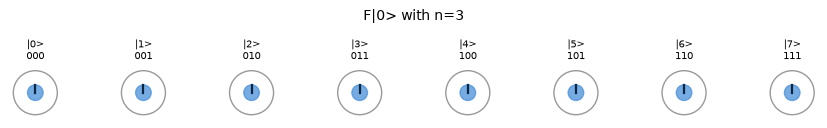

m = 1
  magnitudes: [0.354 0.354 0.354 0.354 0.354 0.354 0.354 0.354]
  phases (deg): [  0.  45.  90. 135. 180. 225. 270. 315.]


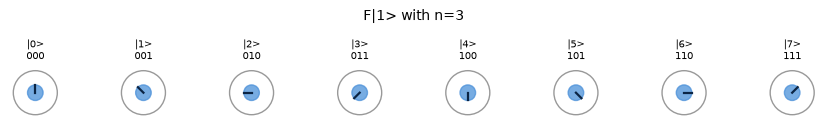

m = 2
  magnitudes: [0.354 0.354 0.354 0.354 0.354 0.354 0.354 0.354]
  phases (deg): [  0.  90. 180. 270. 360.  90. 180. 270.]


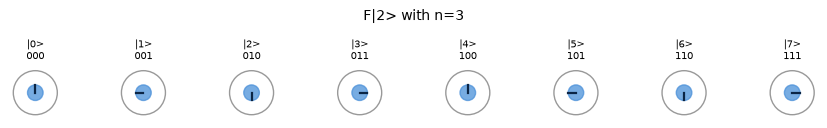

m = 5
  magnitudes: [0.354 0.354 0.354 0.354 0.354 0.354 0.354 0.354]
  phases (deg): [  0. 225.  90. 315. 180.  45. 270. 135.]


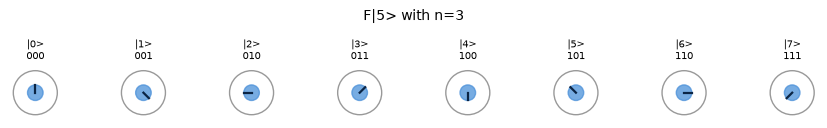

In [38]:
# ✏️ TODO 2.5b: F|m> for m in (0, 1, 2, 5): magnitudes, phases (deg), circle plots
n = 3
d_n = 2**n
F3 = dft_matrix(n)
for m in (0, 1, 2, 5):
    v = F3 @ ket(m, d_n)
    mags = np.abs(v)
    phases = np.degrees(np.angle(v)) % 360
    print(f"m = {m}")
    print("  magnitudes:", np.round(mags, 3))
    print("  phases (deg):", np.round(phases, 1))
    plot_circles(v, f"F|{m}> with n={n}")
    plt.show()

<details><summary>💡 Hint 1</summary>

$F|m\rangle$ is `F @ ket(m, d)`, or simply column `m` of `F`.

</details>

<details><summary>💡 Hint 2</summary>

`np.abs`, `np.angle` (radians), `np.degrees`, then `% 360`.

</details>


## Step 2.6: $F$ as a Qiskit gate

🔀 **Options**

| Option | Code                                                       | Pros                                                                         | Cons                                     |
| ------ | ---------------------------------------------------------- | ---------------------------------------------------------------------------- | ---------------------------------------- |
| A      | `QFTGate(n)`                                               | recommended in the brief; good decomposition; `.inverse()` gives $F^\dagger$ | black box                                |
| B      | build it yourself from H + CPHASE + SWAP (course deck 3.9) | you see every gate; good for the report                                      | more work, easy to get qubit order wrong |
| C      | `UnitaryGate(your_matrix)`                                 | equals your matrix by construction                                           | very expensive to compile (~$4^n$ gates) |

**Most important check of the worksheet:** does Qiskit's `QFTGate` use the same convention as your matrix? If not, encoder and decoder could get swapped without you noticing.

Get the matrix of `QFTGate(N)` with `Operator(...).data` and compare it with your `dft_matrix(N)`.


In [39]:
# ✏️ TODO 2.6: the matrix of Qiskit's QFT gate for N qubits
U_qiskit = Operator(QFTGate(N)).data

In [40]:
check_qftgate(U_qiskit, N)

✅ QFTGate equals your F — Qiskit uses the same +sign convention as the paper


True

<details><summary>💡 Hint 1</summary>

`Operator(gate)` turns a gate into its matrix; `.data` is the NumPy array.

</details>


## Step 2.7 (option B): Build the QFT gate by gate

📖 Ingredients from the course:

- **H**: one qubit into $\tfrac1{\sqrt2}(|0\rangle+e^{i\pi b}|1\rangle)$
- **CPHASE(φ)** (deck 17.B): phase φ only when both qubits are 1. It is symmetric, so it doesn't matter which is the control
- **SWAP** (deck 2.15)

**Recipe** (in words, so you translate it into code):

1. Go through the qubits from the **highest** ($j=n-1$) down to 0.
2. Apply H to qubit $j$.
3. Then, for each lower qubit $q<j$, apply CPHASE with angle $\pi/2^{\,j-q}$ between $q$ and $j$.
4. At the very end, swap qubit $i$ with qubit $n-1-i$ for the first half of the qubits.

✍️ On paper, count the gates: how many H, CPHASE and SWAP for $n=3$? For general $n$? (Course: QFT cost $O(n^2)$.)


In [41]:
# ✏️ TODO 2.7
def qft_manual(n):
    qc = QuantumCircuit(n)
    for j in reversed(range(n)):
        qc.h(j)
        for q in reversed(range(j)):
            qc.cp(np.pi / (2 ** (j - q)), q, j)
    for i in range(n // 2):
        qc.swap(i, n - 1 - i)
    return qc

In [42]:
check_qft_manual(qft_manual)
# print(qft_manual(3).draw('text'))

✅ qft_manual(n) — gates used: ['cp', 'h', 'swap']


True

<details><summary>💡 Hint 1</summary>

Qiskit names: `qc.h(j)`, `qc.cp(angle, q, j)`, `qc.swap(a, b)`.

</details>

<details><summary>💡 Hint 2</summary>

Loops: `for j in reversed(range(n))` and inside `for q in reversed(range(j))`.

</details>


🔬 **Experiment:** remove the SWAPs and run the check again. What message do you get, and why? Then put them back.


## Step 2.8: Chain Task 1 → Task 2 in one circuit

🔀 **Options for adding the QFT to your encoder's circuit**

| Option | Code idea                                                  |
| ------ | ---------------------------------------------------------- |
| A      | `append` the gate as one box on all qubits                 |
| B      | `compose` another circuit (e.g. your `qft_manual`) into it |

Optional: put a `barrier` between the two parts so the drawing shows where Task 1 ends.


In [43]:
# ✏️ TODO 2.8: circuit |0..0> -> |m> -> F|m>
def encode_and_qft(m, n):
    qc = encode_message(m, n)
    qc.barrier()
    qc.append(QFTGate(n), range(n))
    return qc

In [44]:
check_encode_and_qft(encode_and_qft)

✅ encode_and_qft(m, n) — F|m> correct for all m (n = 3 and 6)


True

<details><summary>💡 Hint 1</summary>

Start from `encode_message(m, n)`, then add the QFT.

</details>

<details><summary>💡 Hint 2</summary>

`qc.append(QFTGate(n), range(n))`.

</details>


{np.str_('0000'): np.float64(0.0625), np.str_('0001'): np.float64(0.0625), np.str_('0010'): np.float64(0.06250000000000003), np.str_('0011'): np.float64(0.0625), np.str_('0100'): np.float64(0.0625), np.str_('0101'): np.float64(0.0625), np.str_('0110'): np.float64(0.0625), np.str_('0111'): np.float64(0.0625), np.str_('1000'): np.float64(0.0625), np.str_('1001'): np.float64(0.0625), np.str_('1010'): np.float64(0.06250000000000003), np.str_('1011'): np.float64(0.0625), np.str_('1100'): np.float64(0.0625), np.str_('1101'): np.float64(0.0625), np.str_('1110'): np.float64(0.0625), np.str_('1111'): np.float64(0.0625)}


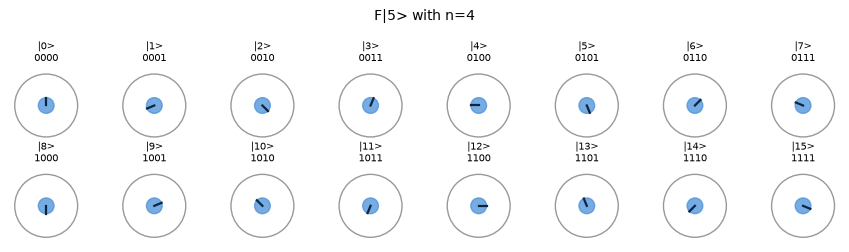

In [45]:
# ✏️ TODO: simulate encode_and_qft(5, N_DEMO): print probabilities and draw it with plot_circles.
# What is the probability of every outcome? Why?
m = 5
n = N_DEMO
qc = encode_and_qft(m, n)
sv = Statevector.from_instruction(qc)
probs = sv.probabilities_dict()
print(probs)
plot_circles(sv, f"F|{m}> with n={n}")
plt.show()

## Step 2.9: $F$ alone is **not** a lock

📖 After $F$, a direct measurement gives a uniformly random number, so it _looks_ hidden. But $F$ is public. Play Eve: take `encode_and_qft(42, N)`, add the inverse QFT (`QFTGate(N).inverse()`), simulate, and read the result.


In [46]:
# ✏️ TODO 2.9: Eve applies F^dagger without any key
m_secret = 42
n = N
qc_eve = encode_and_qft(m_secret, n)
qc_eve.append(QFTGate(n).inverse(), range(n))
sv_eve = Statevector.from_instruction(qc_eve)
probs_eve = sv_eve.probabilities_dict()
m_found = int(max(probs_eve, key=probs_eve.get), 2)
print("Eve found:", m_found)

Eve found: 42


In [47]:
check_eve_unlock(m_found, m_secret)

✅ Eve undoes the public F — F alone hides nothing


True

❓ Write one sentence for your notes: what must be added so Eve can't do this? (This is worksheet 3.)


## Step 2.10 (optional): Cost on hardware

Transpile a circuit containing `QFTGate(n)` with `transpile(qc, basis_gates=["cx","rz","sx","x"])` and count the `cx` gates for $n=2..8$ (`.count_ops()`). Keep the numbers; you'll compare them with the key gate in worksheet 3.


In [48]:
# ✏️ TODO 2.10 (optional)
for n in range(2, 9):
    qc = QuantumCircuit(n)
    qc.append(QFTGate(n), range(n))
    tqc = transpile(qc, basis_gates=["cx", "rz", "sx", "x"])
    ops = tqc.count_ops()
    print(f"n={n}: cx={ops.get('cx', 0)}, total={sum(ops.values())}")

n=2: cx=3, total=17
n=3: cx=6, total=19
n=4: cx=12, total=33
n=5: cx=20, total=51
n=6: cx=30, total=73
n=7: cx=42, total=99
n=8: cx=56, total=129


---

## Self-check questions

1. Probability of each outcome when measuring $F|m\rangle$ with $n=6$?
2. Which gate undoes $F$?
3. Why is the QFT a good first step _before_ adding key phases?

<details><summary>Answers</summary>

1. $1/64$.
2. $F^\dagger$ = `QFTGate(n).inverse()` (not $F$: $F^2|m\rangle=|-m\rangle$).
3. It spreads the message over all $d$ basis states with equal size, so every one of the $d$ key phases acts on something, and magnitudes reveal nothing.
</details>

## Decision log

| Step       | Options                        | My choice | Why |
| ---------- | ------------------------------ | --------- | --- |
| 2.3 matrix | loops / vectorized / FFT       |           |     |
| 2.6 gate   | QFTGate / manual / UnitaryGate |           |     |
| 2.8 adding | append / compose               |           |     |

✅ All green? Continue with **Worksheet 3 (key and $D_k$)**.
